In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm, qmc

In [2]:
EF_GAS = 0.202
EFF_GAS = 0.51
ASSETS = {"DE_POWER": "Power", "TTF_GAS": "Gas", "EUA": "Carbon"}
FACTORS = ["Power", "Gas", "Carbon"]
LABELS = {"Power": "DE baseload power", "Gas": "TTF gas", "Carbon": "EUA carbon", "Spark": "Clean spark spread"}
UNITS = {"Power": "€/MWh", "Gas": "€/MWh", "Carbon": "€/tCO2", "Spark": "€/MWh"}
COLORS = {"Power": "#eb6834", "Gas": "#2a78d6", "Carbon": "#1baf7a", "Spark": "#e87ba4"}
METHOD_COLORS = {"Sobol": "#2a78d6", "Monte Carlo": "#eb6834"}

DT = 1 / 12
T = 5.0
STRIKE = 0.0
R = 0.02
M = 16
M_PATHS = 14
N_REP = 32
SEED = 42

sns.set_theme(style="whitegrid", rc={
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "grid.color": "#e1e0d9", "axes.titlelocation": "left", "axes.titlesize": 12, "legend.frameon": False,
})

In [3]:
data = pd.read_csv("../7/2_Transform/transformed_data.csv", index_col="date", parse_dates=True)
data = data[list(ASSETS)].rename(columns=ASSETS)
data["Spark"] = data["Power"] - (data["Gas"] + EF_GAS * data["Carbon"]) / EFF_GAS
monthly = data.resample("ME").last()

print(f"{data.index[0].date()} -> {data.index[-1].date()}, {len(data)} days, {len(monthly)} month-ends")
data.tail()

2019-01-02 -> 2026-11-09, 2048 days, 95 month-ends


,Power,Gas,Carbon,Spark
date,,,,
2026-11-03,232.33,91.602,89.93,17.098902
2026-11-04,233.68,88.082,90.16,25.259765
2026-11-05,236.37,90.679,88.95,23.336863
2026-11-06,232.94,85.588,86.55,30.839804
2026-11-09,217.60,82.499,87.65,21.120980


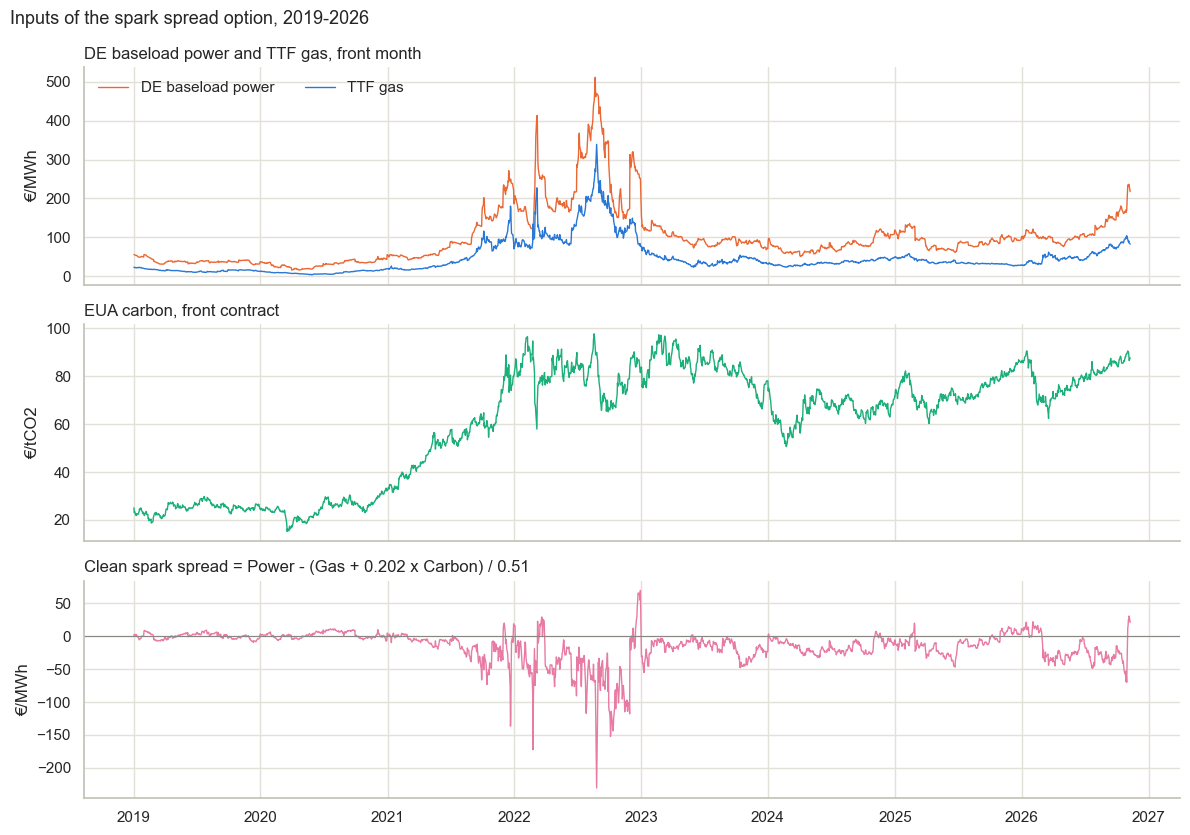

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8.5), sharex=True)
for name in ["Power", "Gas"]:
    axes[0].plot(data.index, data[name], color=COLORS[name], lw=1, label=LABELS[name])
axes[0].legend(loc="upper left", ncols=2)
axes[0].set_title("DE baseload power and TTF gas, front month")
axes[1].plot(data.index, data["Carbon"], color=COLORS["Carbon"], lw=1)
axes[1].set_title("EUA carbon, front contract")
axes[2].plot(data.index, data["Spark"], color=COLORS["Spark"], lw=1)
axes[2].axhline(0, color="#898781", lw=0.8)
axes[2].set_title(f"Clean spark spread = Power - (Gas + {EF_GAS} x Carbon) / {EFF_GAS}")
for ax, name in zip(axes, ["Power", "Carbon", "Spark"]):
    ax.set_ylabel(UNITS[name])
fig.suptitle("Inputs of the spark spread option, 2019-2026", x=0.01, ha="left", fontsize=13)
plt.tight_layout()
plt.show()

In [5]:
def fit_ou(series):
    x = np.log(series)
    b, a = np.polyfit(x.iloc[:-1], x.iloc[1:], 1)
    resid = x.iloc[1:].values - (a + b * x.iloc[:-1].values)
    kappa = -np.log(b) / DT
    sigma = resid.std(ddof=2) * np.sqrt(2 * kappa / (1 - b ** 2))
    return {"kappa": kappa, "theta": a / (1 - b), "sigma": sigma}, resid

In [6]:
fits = {name: fit_ou(monthly[name]) for name in FACTORS}
params = pd.DataFrame({name: fit for name, (fit, _) in fits.items()}).T
rho = pd.DataFrame({name: resid for name, (_, resid) in fits.items()}, index=monthly.index[1:]).corr()

table = params.copy()
table["Long-run level"] = np.exp(table["theta"])
table["Half-life (years)"] = np.log(2) / table["kappa"]
table["Spot today"] = data.iloc[-1]
table.round(3)

,kappa,theta,sigma,Long-run level,Half-life (years),Spot today
Power,0.470,4.773,0.745,118.233,1.476,217.600
Gas,0.429,3.935,0.820,51.139,1.614,82.499
Carbon,0.375,4.476,0.333,87.842,1.847,87.650


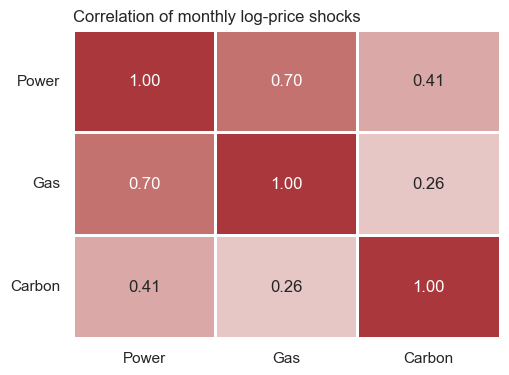

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 4))
sns.heatmap(rho, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, linewidths=2, linecolor="white", cbar=False, ax=ax)
ax.tick_params(axis="y", rotation=0)
ax.set_title("Correlation of monthly log-price shocks")
plt.show()

In [8]:
kappa, theta, sigma = (params[col].values for col in ["kappa", "theta", "sigma"])
x0 = np.log(data[FACTORS].iloc[-1].values)


def ou_mean(x, tau):
    decay = np.exp(-kappa * tau)
    return x * decay + theta * (1 - decay)


def ou_cov(tau):
    k_sum = kappa[:, None] + kappa[None, :]
    return rho.values * np.outer(sigma, sigma) * (1 - np.exp(-k_sum * tau)) / k_sum

In [9]:
def normals(m, d, method, seed):
    if method == "Sobol":
        return norm.ppf(qmc.Sobol(d, scramble=True, rng=seed).random_base2(m))
    return np.random.default_rng(seed).standard_normal((2 ** m, d))

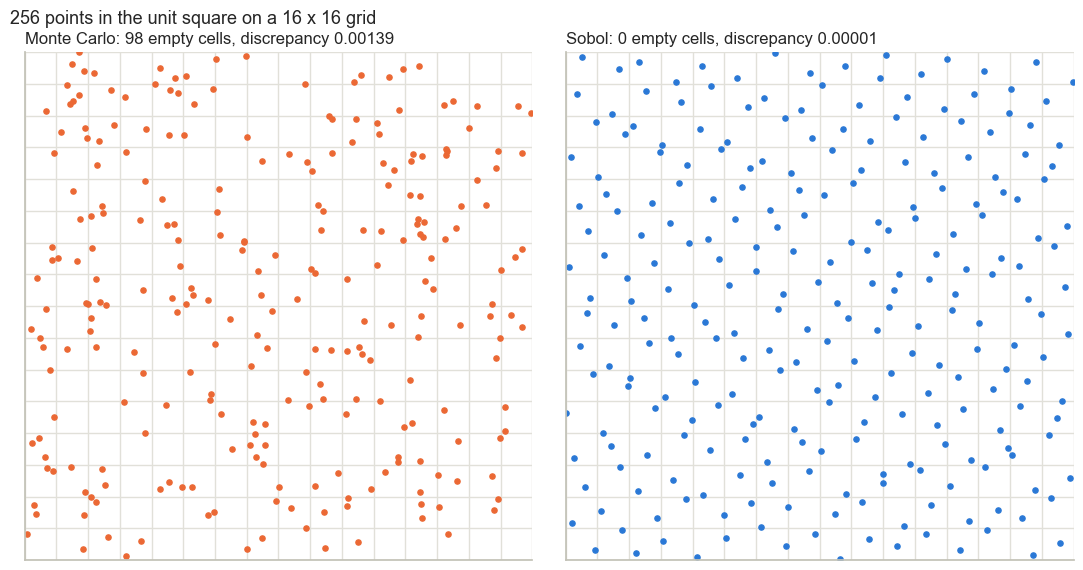

In [10]:
points = {
    "Monte Carlo": np.random.default_rng(SEED).random((256, 2)),
    "Sobol": qmc.Sobol(2, scramble=True, rng=SEED).random_base2(8),
}

fig, axes = plt.subplots(1, 2, figsize=(11, 5.8))
for ax, (method, u) in zip(axes, points.items()):
    empty = 256 - len(np.unique(np.floor(u * 16), axis=0))
    ax.scatter(u[:, 0], u[:, 1], s=14, color=METHOD_COLORS[method])
    ax.set_xticks(np.linspace(0, 1, 17), labels=[])
    ax.set_yticks(np.linspace(0, 1, 17), labels=[])
    ax.set(xlim=(0, 1), ylim=(0, 1), aspect="equal")
    ax.set_title(f"{method}: {empty} empty cells, discrepancy {qmc.discrepancy(u):.5f}")
fig.suptitle("256 points in the unit square on a 16 x 16 grid", x=0.01, ha="left", fontsize=13)
plt.tight_layout()
plt.show()

In [11]:
def spark(prices):
    return prices[..., 0] - (prices[..., 1] + EF_GAS * prices[..., 2]) / EFF_GAS


def terminal_prices(z, tau):
    return np.exp(ou_mean(x0, tau) + z @ np.linalg.cholesky(ou_cov(tau)).T)


def price_call(z, tau, strike):
    return np.exp(-R * tau) * np.maximum(spark(terminal_prices(z, tau)) - strike, 0).mean()

In [12]:
def simulate_paths(m, n_steps, tau, method, seed):
    dt = tau / n_steps
    z = normals(m, 3 * n_steps, method, seed).reshape(-1, n_steps, 3)
    chol = np.linalg.cholesky(ou_cov(dt))
    x = np.empty((2 ** m, n_steps + 1, 3))
    x[:, 0] = x0
    for t in range(n_steps):
        x[:, t + 1] = ou_mean(x[:, t], dt) + z[:, t] @ chol.T
    return np.exp(x)

In [13]:
n_steps = int(T * 12)
paths = simulate_paths(M_PATHS, n_steps, T, "Sobol", SEED)
spark_paths = spark(paths)
dates = pd.date_range(data.index[-1], periods=n_steps + 1, freq=pd.DateOffset(months=1))
path_price = np.exp(-R * T) * np.maximum(spark_paths[:, -1] - STRIKE, 0).mean()

print(f"{2 ** M_PATHS} Sobol paths, {n_steps} monthly steps, Sobol dimension {3 * n_steps}")
print(f"Path-wise price: {path_price:.2f} €/MWh")

16384 Sobol paths, 60 monthly steps, Sobol dimension 180
Path-wise price: 25.88 €/MWh


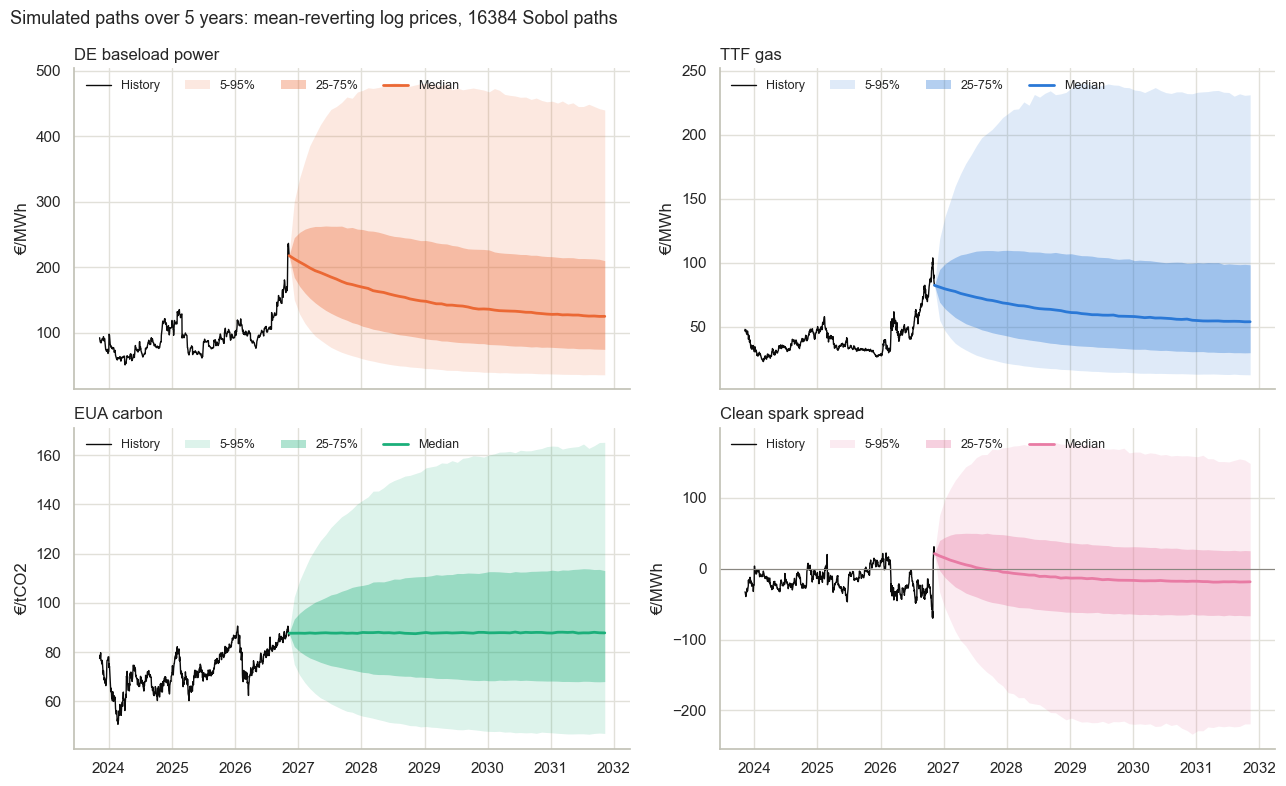

In [14]:
history = data.loc[data.index[-1] - pd.DateOffset(years=3):]
series = {name: paths[..., i] for i, name in enumerate(FACTORS)} | {"Spark": spark_paths}

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
for ax, (name, sims) in zip(axes.flat, series.items()):
    q = np.percentile(sims, [5, 25, 50, 75, 95], axis=0)
    ax.plot(history.index, history[name], color="#0b0b0b", lw=1, label="History")
    ax.fill_between(dates, q[0], q[4], color=COLORS[name], alpha=0.15, lw=0, label="5-95%")
    ax.fill_between(dates, q[1], q[3], color=COLORS[name], alpha=0.35, lw=0, label="25-75%")
    ax.plot(dates, q[2], color=COLORS[name], lw=2, label="Median")
    ax.set_title(LABELS[name])
    ax.set_ylabel(UNITS[name])
    ax.legend(loc="upper left", ncols=4, fontsize=9)
axes[1, 1].axhline(0, color="#898781", lw=0.8)
fig.suptitle(f"Simulated paths over {T:.0f} years: mean-reverting log prices, {2 ** M_PATHS} Sobol paths", x=0.01, ha="left", fontsize=13)
plt.tight_layout()
plt.show()

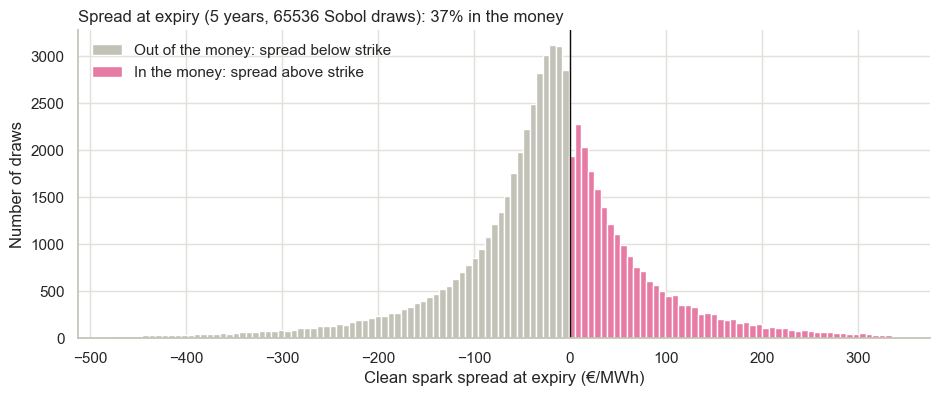

In [15]:
spark_T = spark(terminal_prices(normals(M, 3, "Sobol", SEED), T))
bins = np.linspace(*np.percentile(spark_T, [1, 99]), 121)

fig, ax = plt.subplots(figsize=(11, 4))
ax.hist(spark_T[spark_T <= STRIKE], bins=bins, color="#c3c2b7", label="Out of the money: spread below strike")
ax.hist(spark_T[spark_T > STRIKE], bins=bins, color=COLORS["Spark"], label="In the money: spread above strike")
ax.axvline(STRIKE, color="#0b0b0b", lw=1)
ax.set_xlabel("Clean spark spread at expiry (€/MWh)")
ax.set_ylabel("Number of draws")
ax.set_title(f"Spread at expiry ({T:.0f} years, {2 ** M} Sobol draws): {(spark_T > STRIKE).mean():.0%} in the money")
ax.legend(loc="upper left")
plt.show()

In [16]:
runs = {method: np.array([price_call(normals(M, 3, method, SEED + i), T, STRIKE) for i in range(N_REP)]) for method in METHOD_COLORS}

summary = pd.DataFrame({method: {
    "Price (€/MWh)": p.mean(),
    "Std of one run (€/MWh)": p.std(ddof=1),
    "Std of the average (€/MWh)": p.std(ddof=1) / np.sqrt(N_REP),
} for method, p in runs.items()}).T
ratio = (summary.loc["Monte Carlo", "Std of one run (€/MWh)"] / summary.loc["Sobol", "Std of one run (€/MWh)"]) ** 2

print(f"{N_REP} independent runs of {2 ** M} draws, Sobol re-scrambled at every run")
print(f"Variance reduction of Sobol vs Monte Carlo: x{ratio:.0f}")
summary.round(4)

32 independent runs of 65536 draws, Sobol re-scrambled at every run
Variance reduction of Sobol vs Monte Carlo: x695


,Price (€/MWh),Std of one run (€/MWh),Std of the average (€/MWh)
Sobol,25.9574,0.0083,0.0015
Monte Carlo,25.9493,0.2201,0.0389


In [17]:
def margrabe(tau):
    mean, cov = ou_mean(x0, tau), ou_cov(tau)
    f1 = np.exp(mean[0] + cov[0, 0] / 2)
    f2 = np.exp(mean[1] + cov[1, 1] / 2) / EFF_GAS
    vol = np.sqrt(cov[0, 0] + cov[1, 1] - 2 * cov[0, 1])
    d1 = (np.log(f1 / f2) + vol ** 2 / 2) / vol
    return np.exp(-R * tau) * (f1 * norm.cdf(d1) - f2 * norm.cdf(d1 - vol))


prices_T = terminal_prices(normals(M, 3, "Sobol", SEED), T)
check = pd.Series({
    "Margrabe closed form": margrabe(T),
    "QMC Sobol": np.exp(-R * T) * np.maximum(prices_T[:, 0] - prices_T[:, 1] / EFF_GAS, 0).mean(),
}, name="Dirty spark spread call, strike 0 (€/MWh)")
check["Difference"] = check["QMC Sobol"] - check["Margrabe closed form"]
check.round(4)

Margrabe closed form    42.8615
QMC Sobol               42.8550
Difference              -0.0065
Name: Dirty spark spread call, strike 0 (€/MWh), dtype: float64

In [18]:
reference = price_call(normals(21, 3, "Sobol", 0), T, STRIKE)
ms = np.arange(6, M + 1)
estimates = {
    method: np.array([[price_call(normals(m, 3, method, SEED + i), T, STRIKE) for i in range(N_REP)] for m in ms])
    for method in METHOD_COLORS
}
rmse = pd.DataFrame({method: np.sqrt(((e - reference) ** 2).mean(axis=1)) for method, e in estimates.items()}, index=pd.Index(2 ** ms, name="N"))
slopes = {method: np.polyfit(np.log(rmse.index), np.log(rmse[method]), 1)[0] for method in rmse}

print(f"Reference price ({2 ** 21} Sobol draws): {reference:.4f} €/MWh")
print("Empirical convergence rate: " + ", ".join(f"{method} N^{slope:.2f}" for method, slope in slopes.items()))
rmse.round(4)

Reference price (2097152 Sobol draws): 25.9573 €/MWh
Empirical convergence rate: Sobol N^-0.75, Monte Carlo N^-0.50


,Sobol,Monte Carlo
N,,
64,1.8037,8.3303
128,0.9978,5.0449
256,0.5752,2.9874
512,0.2312,2.6058
1024,0.1995,1.8794
2048,0.1965,1.2003
4096,0.0947,0.8911
8192,0.0427,0.6664
16384,0.0192,0.4693


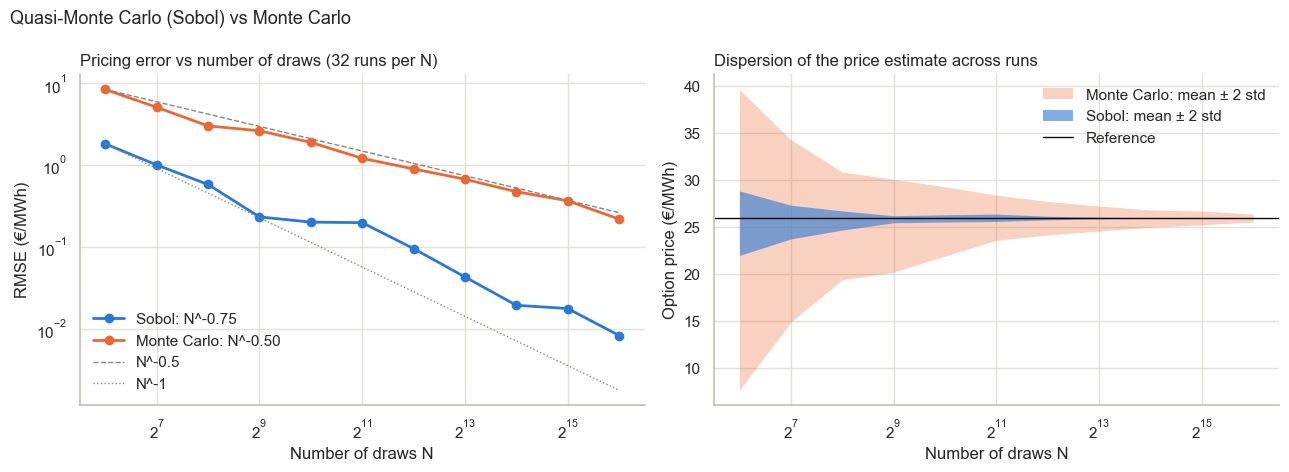

In [19]:
n = rmse.index.values

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for method, color in METHOD_COLORS.items():
    axes[0].plot(n, rmse[method], color=color, lw=2, marker="o", ms=6, label=f"{method}: N^{slopes[method]:.2f}")
for method, color in reversed(METHOD_COLORS.items()):
    e = estimates[method]
    axes[1].fill_between(n, e.mean(axis=1) - 2 * e.std(axis=1), e.mean(axis=1) + 2 * e.std(axis=1), color=color, alpha=0.6 if method == "Sobol" else 0.3, lw=0, label=f"{method}: mean ± 2 std")
axes[0].plot(n, rmse["Monte Carlo"].iloc[0] * (n / n[0]) ** -0.5, color="#898781", lw=1, ls="--", label="N^-0.5")
axes[0].plot(n, rmse["Sobol"].iloc[0] * (n / n[0]) ** -1.0, color="#898781", lw=1, ls=":", label="N^-1")
axes[0].set_yscale("log")
axes[0].set_ylabel("RMSE (€/MWh)")
axes[0].set_title(f"Pricing error vs number of draws ({N_REP} runs per N)")
axes[0].legend(loc="lower left")
axes[1].axhline(reference, color="#0b0b0b", lw=1, label="Reference")
axes[1].set_ylabel("Option price (€/MWh)")
axes[1].set_title("Dispersion of the price estimate across runs")
axes[1].legend(loc="upper right")
for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xlabel("Number of draws N")
fig.suptitle("Quasi-Monte Carlo (Sobol) vs Monte Carlo", x=0.01, ha="left", fontsize=13)
plt.tight_layout()
plt.show()

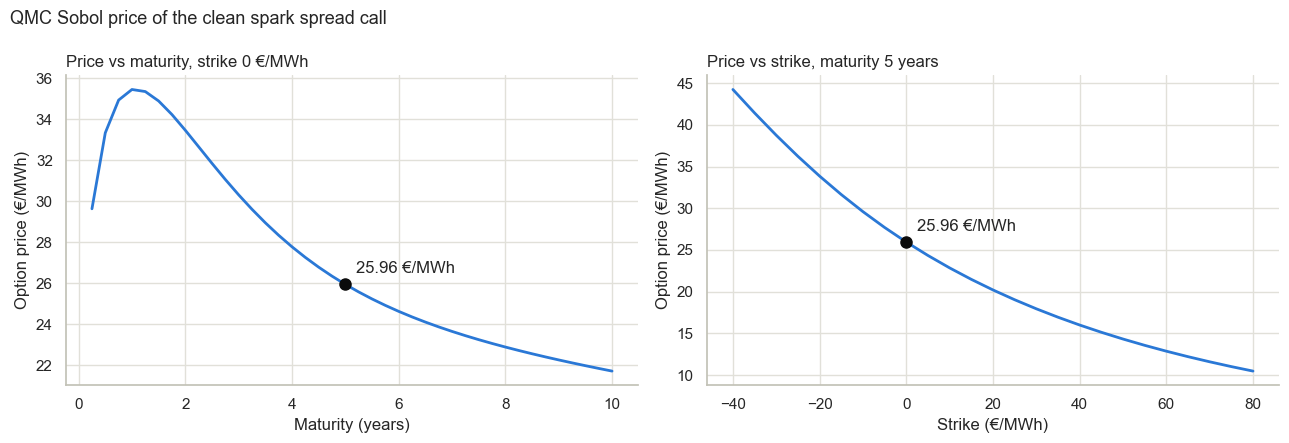

In [20]:
z = normals(M, 3, "Sobol", SEED)
by_maturity = pd.Series({tau: price_call(z, tau, STRIKE) for tau in np.arange(0.25, 10.01, 0.25)})
by_strike = pd.Series({k: price_call(z, T, k) for k in np.arange(-40, 81, 5)})
price = runs["Sobol"].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, curve, x, xlabel, title in [
    (axes[0], by_maturity, T, "Maturity (years)", f"Price vs maturity, strike {STRIKE:.0f} €/MWh"),
    (axes[1], by_strike, STRIKE, "Strike (€/MWh)", f"Price vs strike, maturity {T:.0f} years"),
]:
    ax.plot(curve.index, curve.values, color=METHOD_COLORS["Sobol"], lw=2)
    ax.plot(x, price, "o", color="#0b0b0b", ms=8)
    ax.annotate(f"{price:.2f} €/MWh", (x, price), xytext=(8, 8), textcoords="offset points")
    ax.set(xlabel=xlabel, ylabel="Option price (€/MWh)", title=title)
fig.suptitle("QMC Sobol price of the clean spark spread call", x=0.01, ha="left", fontsize=13)
plt.tight_layout()
plt.show()

In [21]:
mc_draws = 2 ** M * ratio

print(f"Clean spark spread call on 1 MWh, expiry {dates[-1].date()} ({T:.0f} years), strike {STRIKE:.0f} €/MWh")
print(f"Spread today: {data['Spark'].iloc[-1]:.2f} €/MWh, expected at expiry: {spark_T.mean():.2f} €/MWh")
print(f"QMC Sobol price: {price:.2f} €/MWh, std {runs['Sobol'].std(ddof=1):.4f} with {2 ** M} draws")
print(f"Monte Carlo needs about {mc_draws / 1e6:.0f} million draws for the same accuracy")

Clean spark spread call on 1 MWh, expiry 2031-11-09 (5 years), strike 0 €/MWh
Spread today: 21.12 €/MWh, expected at expiry: -25.36 €/MWh
QMC Sobol price: 25.96 €/MWh, std 0.0083 with 65536 draws
Monte Carlo needs about 46 million draws for the same accuracy
